In [ ]:
import pandas as pd, os, json, numpy as np
path="Artworks_dates_analysis (1).csv"
df=pd.read_csv(path, low_memory=False)
df.shape, df.columns.tolist()[:50], df.head(3).to_dict('records')


((155118, 34),
 ['Title',
  'Artist',
  'ConstituentID',
  'ArtistBio',
  'Nationality',
  'BeginDate',
  'EndDate',
  'Gender',
  'Date',
  'Medium',
  'Dimensions',
  'CreditLine',
  'AccessionNumber',
  'Classification',
  'Department',
  'DateAcquired',
  'Cataloged',
  'ObjectID',
  'URL',
  'ImageURL',
  'OnView',
  'Circumference (cm)',
  'Depth (cm)',
  'Diameter (cm)',
  'Height (cm)',
  'Length (cm)',
  'Weight (kg)',
  'Width (cm)',
  'Seat Height (cm)',
  'Duration (sec.)',
  'year_lower',
  'year_upper',
  'year_mid',
  'date_type'],
 [{'Title': 'Ferdinandsbrücke Project, Vienna, Austria (Elevation, preliminary version)',
   'Artist': 'Otto Wagner',
   'ConstituentID': '6210',
   'ArtistBio': '(Austrian, 1841–1918)',
   'Nationality': '(Austrian)',
   'BeginDate': '(1841)',
   'EndDate': '(1918)',
   'Gender': '(male)',
   'Date': '1896',
   'Medium': 'Ink and cut-and-pasted painted pages on paper',
   'Dimensions': '19 1/8 x 66 1/2" (48.6 x 168.9 cm)',
   'CreditLine': 'F

Cataloging status by creation decade:


,CreationDecade,Total_Records,Cataloged_Records,Cataloged_Rate,Uncataloged_Records,Uncataloged_Rate
5,1790,82,1,0.012195,81,0.987805
7,1810,327,324,0.990826,3,0.009174
9,1830,88,7,0.079545,81,0.920455
10,1840,251,70,0.278884,181,0.721116
11,1850,832,308,0.370192,524,0.629808
12,1860,954,734,0.769392,220,0.230608
13,1870,924,518,0.560606,406,0.439394
14,1880,554,333,0.601083,221,0.398917
15,1890,2678,1785,0.666542,893,0.333458
16,1900,4590,3076,0.670153,1514,0.329847



Creation-year summary by cataloging status:


,count,mean,median,std,min,max
Cataloged,,,,,,
N,52233,1948.979850,1950.0,29.99186,1798.0,2026.0
Y,102885,1960.636186,1966.0,35.29129,249.5,2026.0


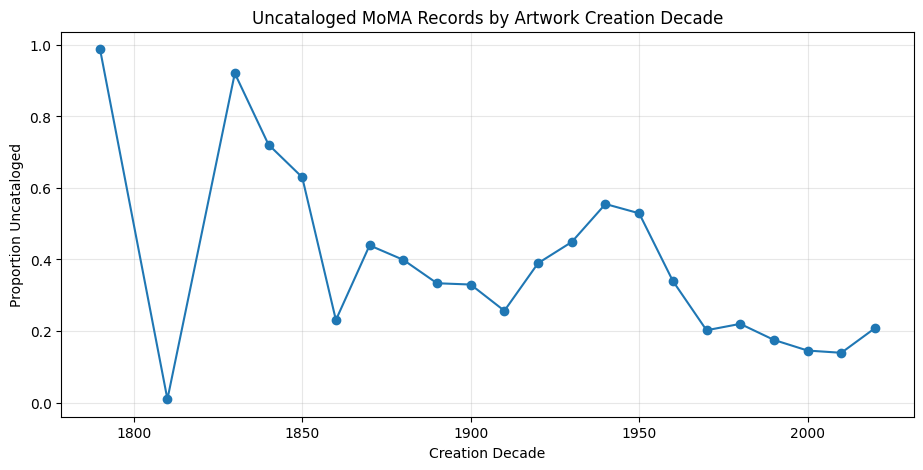

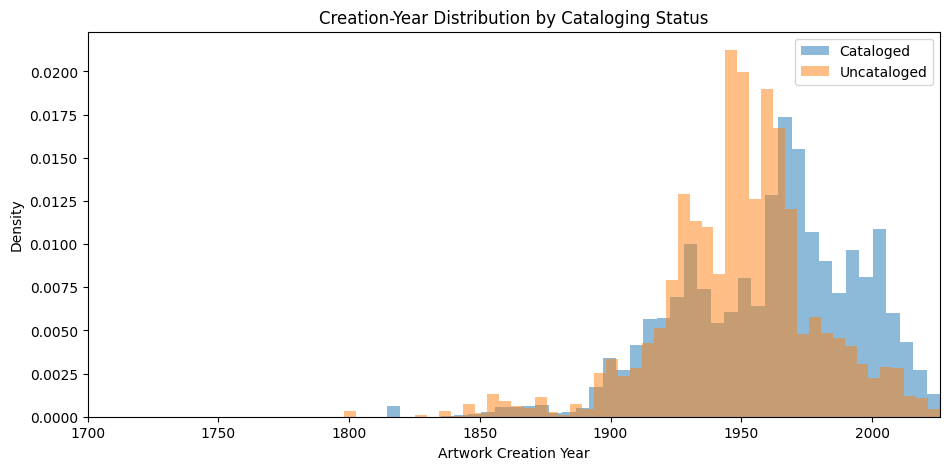


Decades with the highest uncataloged rates:


,CreationDecade,Total_Records,Uncataloged_Records,Uncataloged_Rate
5,1790,82,81,0.987805
9,1830,88,81,0.920455
10,1840,251,181,0.721116
11,1850,832,524,0.629808
20,1940,15464,8583,0.555031
21,1950,15577,8240,0.528985
19,1930,14189,6368,0.448798
13,1870,924,406,0.439394
14,1880,554,221,0.398917
18,1920,12535,4883,0.389549


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. LOAD CLEANED MOMA DATA
# ============================================================

df = pd.read_csv("Artworks_dates_analysis (1).csv", low_memory=False)

# Keep only records with a usable creation year and valid cataloging status
analysis = df[
    df["year_mid"].notna() &
    df["Cataloged"].isin(["Y", "N"])
].copy()


# ============================================================
# 2. CREATE BINARY CATALOGING VARIABLE
# ============================================================

# Cataloged = 1
# Uncataloged = 0
analysis["Cataloged_binary"] = analysis["Cataloged"].map({
    "Y": 1,
    "N": 0
})


# ============================================================
# 3. CREATE CREATION DECADE
# ============================================================

# Example:
# 1968 -> 1960
# 1995 -> 1990
analysis["CreationDecade"] = (
    np.floor(analysis["year_mid"] / 10) * 10
).astype(int)


# ============================================================
# 4. SUMMARIZE CATALOGING STATUS BY CREATION DECADE
# ============================================================

decade_summary = (
    analysis
    .groupby("CreationDecade")
    .agg(
        Total_Records=("ObjectID", "count"),
        Cataloged_Records=("Cataloged_binary", "sum"),
        Cataloged_Rate=("Cataloged_binary", "mean")
    )
    .reset_index()
)

# Calculate uncataloged counts and rates
decade_summary["Uncataloged_Records"] = (
    decade_summary["Total_Records"]
    - decade_summary["Cataloged_Records"]
)

decade_summary["Uncataloged_Rate"] = (
    1 - decade_summary["Cataloged_Rate"]
)

# Keep decades with enough records to avoid unstable rates
# You can change 50 to another threshold if needed
decade_summary_plot = decade_summary[
    decade_summary["Total_Records"] >= 50
].copy()

print("Cataloging status by creation decade:")
display(decade_summary_plot)


# ============================================================
# 5. OVERALL CATALOGED VS. UNCATALOGED SUMMARY
# ============================================================

status_summary = (
    analysis
    .groupby("Cataloged")
    ["year_mid"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

print("\nCreation-year summary by cataloging status:")
display(status_summary)


# ============================================================
# 6. PLOT UNCATALOGED RATE BY CREATION DECADE
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(
    decade_summary_plot["CreationDecade"],
    decade_summary_plot["Uncataloged_Rate"],
    marker="o"
)

plt.xlabel("Creation Decade")
plt.ylabel("Proportion Uncataloged")
plt.title("Uncataloged MoMA Records by Artwork Creation Decade")

plt.grid(alpha=0.3)
plt.show()



# ============================================================
# 7. COMPARE CREATION-YEAR DISTRIBUTIONS
#    CATALOGED VS. UNCATALOGED
#    Display only years from 1700 onward
# ============================================================

# Restrict the visualization to artworks created from 1700 onward.
# This avoids the very small number of extremely early records
# stretching the x-axis and making the main distribution difficult to read.
plot_data = analysis[
    analysis["year_mid"] >= 1700
].copy()

cataloged_years = plot_data.loc[
    plot_data["Cataloged"] == "Y",
    "year_mid"
]

uncataloged_years = plot_data.loc[
    plot_data["Cataloged"] == "N",
    "year_mid"
]

plt.figure(figsize=(11, 5))

plt.hist(
    cataloged_years,
    bins=50,
    density=True,
    alpha=0.5,
    label="Cataloged"
)

plt.hist(
    uncataloged_years,
    bins=50,
    density=True,
    alpha=0.5,
    label="Uncataloged"
)

# Set the visible x-axis range
plt.xlim(1700, plot_data["year_mid"].max())

plt.xlabel("Artwork Creation Year")
plt.ylabel("Density")
plt.title("Creation-Year Distribution by Cataloging Status")
plt.legend()

plt.show()


# ============================================================
# 8. IDENTIFY DECADES WITH THE HIGHEST UNCATALOGED RATES
# ============================================================

highest_uncataloged = (
    decade_summary_plot
    .sort_values(
        "Uncataloged_Rate",
        ascending=False
    )
    .head(10)
)

print("\nDecades with the highest uncataloged rates:")
display(
    highest_uncataloged[
        [
            "CreationDecade",
            "Total_Records",
            "Uncataloged_Records",
            "Uncataloged_Rate"
        ]
    ]
)